<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/gurultu_DFT_analizi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

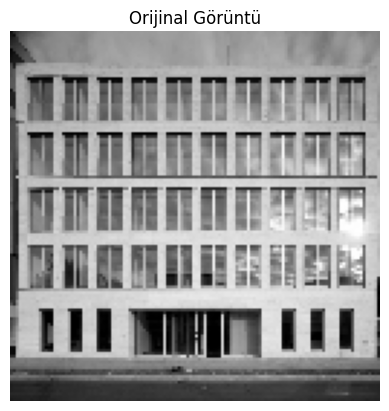

In [3]:
resim = cv2.imread("image09.jpeg", cv2.IMREAD_GRAYSCALE)

if resim is None:
    raise FileNotFoundError("Görsel bulunamadı!")

resim = cv2.resize(resim, (128, 128))

plt.imshow(resim, cmap="gray")
plt.title("Orijinal Görüntü")
plt.axis("off")
plt.show()

In [4]:
def gauss_gurultusu(goruntu, sigma):

    gurultu = np.random.normal(
        0,
        sigma,
        goruntu.shape
    )

    sonuc = goruntu.astype(float) + gurultu

    sonuc = np.clip(sonuc, 0, 255)

    return sonuc.astype(np.uint8)

In [5]:
def salt_pepper_gurultusu(goruntu, oran):

    if not 0 <= oran <= 1:
        raise ValueError("Oran 0 ile 1 arasında olmalıdır!")

    sonuc = goruntu.copy()

    toplam = sonuc.size
    adet = int(toplam * oran)

    indeksler = np.random.choice(
        toplam,
        adet,
        replace=False
    )

    duz = sonuc.ravel()

    yari = adet // 2

    duz[indeksler[:yari]] = 0
    duz[indeksler[yari:]] = 255

    return sonuc

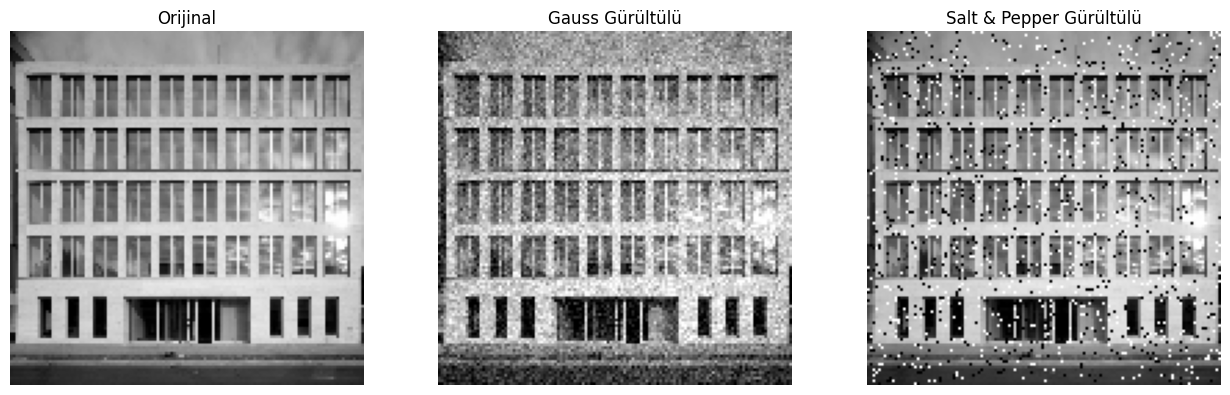

In [6]:
np.random.seed(42)

gauss_resim = gauss_gurultusu(resim, sigma=25)

sp_resim = salt_pepper_gurultusu(resim, oran=0.08)

plt.figure(figsize=(13, 4))

resimler = [
    (resim, "Orijinal"),
    (gauss_resim, "Gauss Gürültülü"),
    (sp_resim, "Salt & Pepper Gürültülü")
]

for i, (gorsel, baslik) in enumerate(resimler):
    plt.subplot(1, 3, i + 1)
    plt.imshow(gorsel, cmap="gray", vmin=0, vmax=255)
    plt.title(baslik)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
def dft2_hesapla(goruntu):

    M, N = goruntu.shape

    m = np.arange(M)
    n = np.arange(N)

    W1 = np.exp(
        -2j * np.pi * np.outer(m, m) / M
    )

    W2 = np.exp(
        -2j * np.pi * np.outer(n, n) / N
    )

    harmonik = W1 @ goruntu @ W2.T

    return harmonik

In [8]:
H_orijinal = dft2_hesapla(resim)

H_gauss = dft2_hesapla(gauss_resim)

H_sp = dft2_hesapla(sp_resim)

print("Orijinal:", H_orijinal.shape)
print("Gauss:", H_gauss.shape)
print("Salt & Pepper:", H_sp.shape)

np.save("harmonik_orijinal.npy", H_orijinal)
np.save("harmonik_gauss.npy", H_gauss)
np.save("harmonik_salt_pepper.npy", H_sp)

Orijinal: (128, 128)
Gauss: (128, 128)
Salt & Pepper: (128, 128)


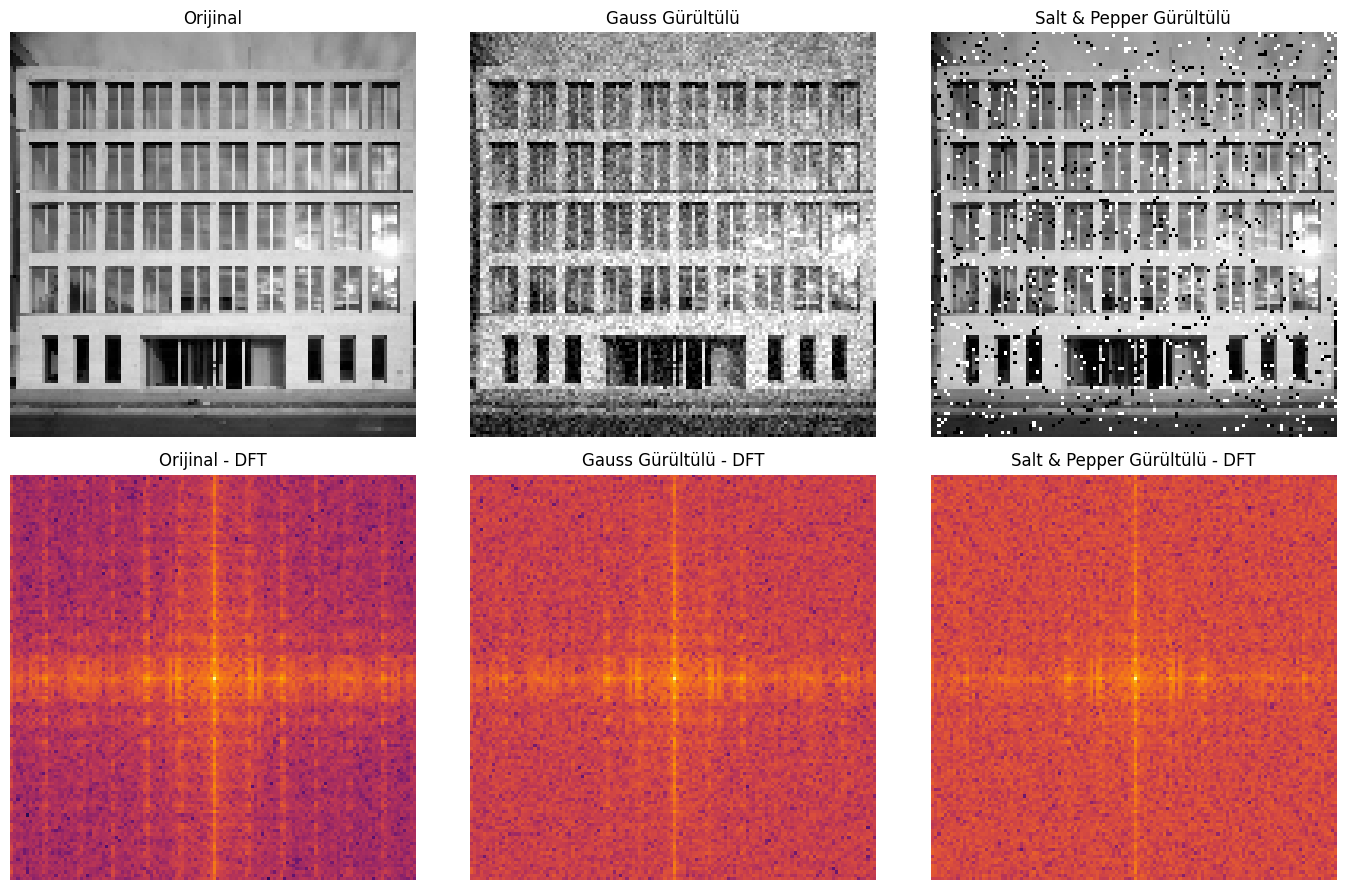

In [9]:
matrisler = [H_orijinal, H_gauss, H_sp]

spektrumlar = [
    np.log1p(np.abs(np.fft.fftshift(H)))
    for H in matrisler
]

plt.figure(figsize=(14, 9))

for i in range(3):

    plt.subplot(2, 3, i + 1)
    plt.imshow(
        resimler[i][0],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    plt.title(resimler[i][1])
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(
        spektrumlar[i],
        cmap="inferno",
        vmin=0,
        vmax=max(s.max() for s in spektrumlar)
    )
    plt.title(resimler[i][1] + " - DFT")
    plt.axis("off")

plt.tight_layout()

plt.savefig("odev38_dft_karsilastirma.png", dpi=200)

plt.show()

In [10]:
fark_gauss = np.mean(
    np.abs(H_orijinal - H_gauss)
)

fark_sp = np.mean(
    np.abs(H_orijinal - H_sp)
)

print("Gauss harmonik farkı:", round(fark_gauss, 2))
print("Salt & Pepper harmonik farkı:", round(fark_sp, 2))

Gauss harmonik farkı: 2769.13
Salt & Pepper harmonik farkı: 4567.21


### Sonuç ve Yorum

Bu çalışmada orijinal görüntüye Gauss ve Salt & Pepper gürültüleri eklenerek görüntülerin 2 boyutlu DFT analizleri yapılmıştır. Gauss gürültüsü görüntüde rastgele parlaklık değişimleri oluştururken Salt & Pepper gürültüsü siyah ve beyaz noktalar meydana getirmiştir.

Harmonik matrisler karşılaştırıldığında Gauss gürültüsü için ortalama fark 2769,13, Salt & Pepper gürültüsü için ise 4567,21 olarak hesaplanmıştır. Bu sonuçlara göre kullanılan gürültü seviyelerinde Salt & Pepper gürültüsünün frekans uzayında daha fazla değişime neden olduğu görülmüştür. Her iki gürültü türünün de görüntünün frekans bileşenlerini etkilediği gözlemlenmiştir.